# Methodology 


- for any phase where signal stays constant. 
    - print(np.full(3,7))
- for any phase signal where value goes up or down. 
    - print(np.linspace(0,10))
- glue these arrays together end to end. 
    - print(np.concatenate([np.full(3,7), np.linspace(0,10,5)]))
- Like range(4) as an array. for time count. If current has 300 values for example, we want 0 to 299. 
    - print(np.arange(4))

# 5 phases for charging decided: 
""" 
    - Waiting: plugged in but not yet charging. Current is 0, held constant. 
    - Ramp: current rises from 0 to 16A. 
    - Plateau: charging at full current, held constant at 16A, back to 0. 
    - Taper: the battery is nearly full, so current falls from 16 back to 0. 
    - Done: charging finished but still pluggedd in. current is 0. 

"""

In [ ]:
# FIRST FUNCTION: 
# simulate_sessions
# inputs: random generator
# outputs: dataframe with columns time, current, voltage, power, charging_status and pilot_status
# Phase_lenght and values: write down the numbers that I want (waiting 30-60 s, max current 16A, max power 4kw etc)

import numpy as np
import pandas as pd

def simulate_sessions(): 
    wait_len = 5 # seconds
    plateau_len = 60 # seconds 
    ramp_len = 30 # seconds 
    taper_len = 15 # seconds
    done_len = 5 # seconds 
    
    max_current = 16 # Amperes
    min_current = 0 # Amperes
    
    # CURRENT PHASES 
    current_waiting = np.full(wait_len,min_current) # plugged in but not yet charging. 
    current_ramp = np.linspace(0, max_current, ramp_len) # current rises from 0 0 to 16A.
    current_plateau = np.full(plateau_len, max_current) # charging full current, 16 A constant.  
    current_taper = np.linspace(max_current,min_current, taper_len) # battery nearly full, 16 to 0. 
    current_done = np.full(done_len,min_current) # charged but still plugged. 
    current_concatenated = np.concatenate([current_waiting, current_ramp, current_plateau, current_taper, current_done]) # concatenating into an array the current from the charging session. 
    
    # TIME PHASES 
    # time column stays correct automatically when I change a phase length.
    time_session = np.arange(len(current_concatenated))
    
    # Dataframe object creation 
    df = pd.DataFrame({
        "current": current_concatenated, 
        "time": time_session
    })
    
    return df



NameError: name 'df' is not defined

   current  time
0      0.0     0
1      0.0     1
2      0.0     2
3      0.0     3
4      0.0     4


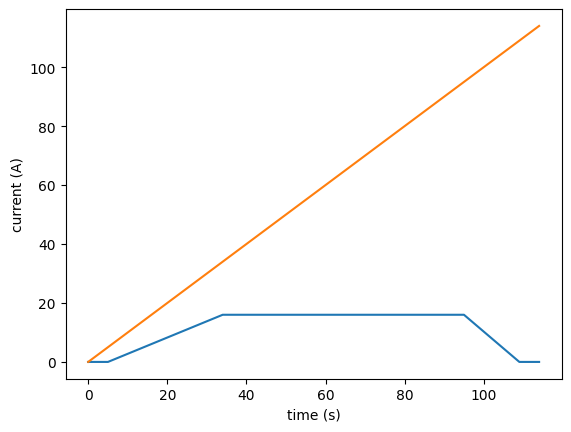

In [ ]:
import matplotlib.pyplot as plt 

current = simulate_sessions()

plt.plot(current)
plt.xlabel("time (s)")
plt.ylabel("current (A)")
plt.show()

In [7]:
# print Dataframe
print(current.head())

print(current.tail())

   current  time
0      0.0     0
1      0.0     1
2      0.0     2
3      0.0     3
4      0.0     4
     current  time
110      0.0   110
111      0.0   111
112      0.0   112
113      0.0   113
114      0.0   114
